# Readout errors and their mitigation

Measurement is often the largest single error on superconducting devices. The twins apply each qubit's readout confusion,
p(read 1 | 0) and p(read 0 | 1). This notebook measures it, shows how it scales with the number of qubits, and removes it
from a result with the standard tensored-inverse mitigation.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': 'c88add07efb8:7:a77a42',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. Reading |0⟩ and |1⟩

Prepare all-zeros and all-ones on five qubits with only readout noise switched on. The fraction read correctly is the readout fidelity to the fifth power.

In [2]:
READOUT_ONLY = {"model": "device", "depolarizing": False, "relaxation": False, "idle": False, "coherent": False, "crosstalk": False}
zeros, ones = program(5, []), program(5, [f"x q[{i}]" for i in range(5)])
rows = []
for b in ALL_BACKENDS:
    rows.append({"twin": NAMES[b],
                 "P(read 00000 | 00000)": success(run(b, zeros, shots=50000, noise=READOUT_ONLY, routing=True), ["00000"]),
                 "P(read 11111 | 11111)": success(run(b, ones, shots=50000, noise=READOUT_ONLY, routing=True), ["11111"])})
pd.DataFrame(rows).set_index("twin").round(4)

,P(read 00000 | 00000),P(read 11111 | 11111)
twin,,
Helios,0.9985,0.9985
Forte,0.9748,0.9755
Ankaa-3,0.8602,0.8607
Emerald,0.8602,0.8607
Heron r3,0.9983,0.9889
Nighthawk,0.9682,0.9524
Willow,0.9890,0.9601


## 2. Readout error grows with width

With readout as the only error, GHZ success falls as the readout fidelity to the power n.

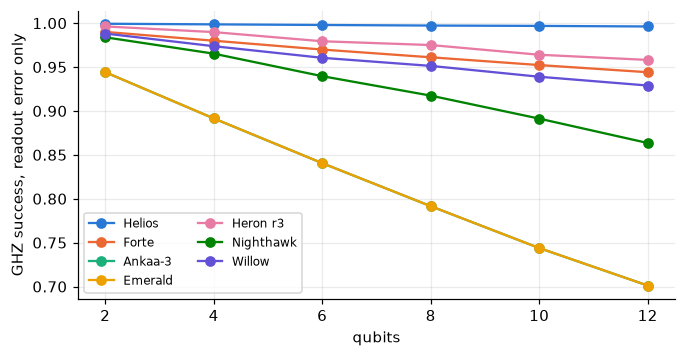

In [3]:
widths = [2, 4, 6, 8, 10, 12]
fig, ax = plt.subplots(figsize=(7, 3.4))
for b in ALL_BACKENDS:
    ys = [success(run(b, ghz(n), shots=20000, noise=READOUT_ONLY, routing=True), ["0" * n, "1" * n]) for n in widths]
    ax.plot(widths, ys, "o-", color=COLORS[b], label=NAMES[b])
ax.set_xlabel("qubits"); ax.set_ylabel("GHZ success, readout error only"); ax.legend(ncols=2, fontsize=8); plt.show()

Ankaa-3 and Emerald use the same assumed 97 % readout fidelity, so their curves coincide and only one is visible.

## 3. Calibrating the confusion matrix

Two calibration circuits (all zeros, all ones) give each qubit's 2×2 confusion matrix, here with the full device noise model, as one would on hardware.

In [4]:
def confusion(backend, n):
    zero = run(backend, program(n, []), shots=100000, noise=True)["result"]["counts"]
    one = run(backend, program(n, [f"x q[{i}]" for i in range(n)]), shots=100000, noise=True)["result"]["counts"]
    mats = []
    for q in range(n):                       # bit q is character n-1-q of a count key
        e01 = sum(v for k, v in zero.items() if k[n - 1 - q] == "1") / 100000   # read 1 when 0
        e10 = sum(v for k, v in one.items() if k[n - 1 - q] == "0") / 100000    # read 0 when 1
        mats.append(np.array([[1 - e01, e10], [e01, 1 - e10]]))
    return mats

mats = confusion("rigetti_ankaa_3", 5)
pd.DataFrame([{"qubit": q, "p(1|0)": m[1, 0], "p(0|1)": m[0, 1]} for q, m in enumerate(mats)]).set_index("qubit").round(4)

,p(1|0),p(0|1)
qubit,,
0,0.0299,0.0315
1,0.0292,0.0320
2,0.0292,0.0313
3,0.0300,0.0309
4,0.0304,0.0307


## 4. Mitigating a GHZ result

Inverting the tensor product of the per-qubit matrices removes most of the readout error from the measured distribution (the remaining error is from gates and relaxation).

In [5]:
def mitigate(counts, mats):
    n = len(mats)
    p = np.zeros(2 ** n)
    for k, v in counts.items():
        p[int(k, 2)] = v
    p /= p.sum()
    inverse = np.array([[1.0]])
    for m in reversed(mats):                 # kron order: highest qubit first, matching int(key, 2)
        inverse = np.kron(inverse, np.linalg.inv(m))
    q = np.clip(inverse @ p, 0, None)
    return {format(i, f"0{n}b"): x for i, x in enumerate(q / q.sum())}

raw = run("rigetti_ankaa_3", ghz(5), shots=200000, noise=True)
fixed = mitigate(raw["result"]["counts"], mats)
print("GHZ5 success, raw:       ", round(success(raw, ["00000", "11111"]), 4))
print("GHZ5 success, mitigated: ", round(fixed["00000"] + fixed["11111"], 4))
print("GHZ5 success without readout error (same twin):",
      round(success(run("rigetti_ankaa_3", ghz(5), shots=200000, noise={"model": "device", "readout": False}), ["00000", "11111"]), 4))

GHZ5 success, raw:        0.8014
GHZ5 success, mitigated:  0.9342
GHZ5 success without readout error (same twin): 0.9304


## Takeaways

- Readout error compounds with the number of measured qubits.
- A tensored confusion matrix, measured with two circuits, removes most of it from a distribution.